# Codesign with Catapult: Virtex-7 FPGA

Copy of `codesign_catapult.ipynb` (2026-10-27) for an FPGA study: `QMlp_Slim`
synthesized with Catapult 2024.2_2 for the Xilinx Virtex-7 `xc7vx485tffg1157-1`
(Catapult library `mgc_Xilinx-VIRTEX-7-1_beh`, Vivado flow), with the weights
hardcoded in the design (`programmable_weights = False`) instead of exposed as
inputs as in the ASIC (TSMC 28 nm) notebook.

Differences from `codesign_catapult.ipynb`:
- `model_type = 'QMlp_Slim'`
- "Configure hls4ml model": `tech = "fpga"`, `part = fpga_part`, no ASIC libraries,
  `programmable_weights = False` (so no `BramFactor = 0`), project folder
  `SmtPxl_QMlp_Slim_io_parallel_Latency_efpga_hls4ml_prj`
- files written to the repo root (`.dat`, `.png`, `.jpeg`, `.yml`, `.parquet`)
  carry the `run_tag` suffix, so the two notebooks do not overwrite each other

The area in the Catapult report is Catapult's own estimate (LUT-equivalent area score),
not LUT/FF/DSP counts from Vivado.


## List trained models

In [1]:
# Models trained on the ROI dataset (two_bit_optimization.ipynb with use_roi=True, roi_dataset='2s').
# Each directory name encodes the model_type and its fingerprint, both needed below.
!ls -d smart-pixels/weights/dataset_2s_roi_weights/*-2bit_optimized-*-checkpoints

smart-pixels/weights/dataset_2s_roi_weights/weights-2t-Conv1D_Slim-2bit_optimized-3eb13b90-checkpoints
smart-pixels/weights/dataset_2s_roi_weights/weights-2t-Conv2D_Slim-2bit_optimized-392456de-checkpoints
smart-pixels/weights/dataset_2s_roi_weights/weights-2t-Mlp_Slim-2bit_optimized-392456de-checkpoints
smart-pixels/weights/dataset_2s_roi_weights/weights-2t-QConv1D_Slim-2bit_optimized-3eb13b90-checkpoints
smart-pixels/weights/dataset_2s_roi_weights/weights-2t-QMlp_Slim-2bit_optimized-392456de-checkpoints


## Setup

Please follow [these instructions](https://github.com/GiuseppeDiGuglielmo/catapult_venvs) to setup an environment for Catapult AI NN (_hls4ml_).

You can either use the _hls4ml_ release with Catapult (2024.2_1) or point to a Siemens or official GitHub repository. [Here we provide some details.](https://github.com/GiuseppeDiGuglielmo/catapult_compare_releases)

In [2]:
# Path to the Catapult installation directory
!echo $MGC_HOME

/extras2/tools/Siemens/catapult/2024.2_2/Mgc_home


In [3]:
# Path to the hls4ml installation directory
# It can be point to either the Catapult installation directory or a copy of Siemens/Official GitHub repo 
!echo $PYTHONPATH

/extras2/tools/Siemens/catapult/2024.2_2/Mgc_home/shared/pkgs/ccs_hls4ml/hls4ml


In [4]:
# For non-quantized models: Conv2D_Max, Conv2D_Full, Conv2D_Slim, Conv1D_Full, Conv1D_Slim, Mlp_Full, Mlp_Slim
# For quantized models: QConv2D_Max, QConv2D_Full, QConv2D_Slim, QConv1D_Full, QConv1D_Slim, QMlp_Full, QMlp_Slim
model_type = 'QMlp_Slim'

# Xilinx Virtex-7. Catapult 2024.2_2 maps this part to mgc_Xilinx-VIRTEX-7-1_beh
# (setup_xilinx_part in build_prj.tcl; checked 2026-10-27). An unknown part does
# not stop the run: build_prj.tcl warns "Could not find specific Xilinx base
# library" and falls back to KINTEX-u, see the check after synthesis.
fpga_part = "xc7vx485tffg1157-1"

# Suffix of the files this notebook writes to the repo root (.dat, .png, ...),
# so they do not overwrite those of codesign_catapult.ipynb. Defined here
# because the "Save .dat files" cell needs it before "Configure hls4ml model".
run_tag = f"{model_type}_{fpga_part}"

## Import libraries

Disable some console warnings on the ASIC-group servers

In [5]:
import os

In [6]:
os.environ["TF_XLA_FLAGS"] = "--tf_xla_enable_xla_devices"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

In [7]:
import sys
sys.path.insert(0, "./two_bit_optimization_helpers")  # run this notebook from the repo root

In [8]:
import hls4ml
# submodule is not pulled in by "import hls4ml" alone; cell using get_ymodel_keras needs it
import hls4ml.model.profiling

import numpy as np
import math
import tensorflow as tf
import yaml
import json
from two_bit_optimization_helpers import *

from matplotlib import colors
import matplotlib.pyplot as plt

from two_bit_optimization_helpers.loss import *
from qkeras import quantized_bits

from two_bit_optimization_helpers.codesign_utils import *

In [9]:
!ls /extras2/home/gdg/research/projects/smartpixels/VIAS/fermi_roi_finder/implementation/testbench/cocotb/roi_finder/sim_out/dataset_2s_48x192_50x12P5_parquets/

test  TFR_files  train


## Set parameters

In [10]:
# ROI dataset produced by the VIAS roi_finder testbench (labels corrected, see VIAS commit 248aeed)
dataset_base_dir = "/extras2/home/gdg/research/projects/smartpixels/VIAS/fermi_roi_finder/implementation/testbench/cocotb/roi_finder/sim_out/dataset_2s_48x192_50x12P5_parquets/"

# .npy inputs are written by save_data_as_npy() at the end of two_bit_optimization.ipynb
npy_dir_val = os.path.join("npy")

# NOTE: tfrecords_dir_train/val used to be defined here but were never read anywhere in this
# notebook - the model is loaded from HDF5 and the data from .npy - so they were removed.

In [11]:
# batch_size = 5000
# train_file_size = len(os.listdir(dataset_train_dir))
# val_file_size = len(os.listdir(dataset_validation_dir))

In [12]:
# ROI weights written by two_bit_optimization.ipynb (use_roi=True, roi_dataset='2s').
# ./best-model/ is not used any more - clean.sh deletes it.
base_dir = 'smart-pixels/weights/dataset_2s_roi_weights/'

fingerprint_choices = {
    # non-quantized models
    'Conv2D_Max'  : '392456de',
    'Conv2D_Full' : '392456de',
    'Conv2D_Slim' : '392456de',
    'Conv1D_Full' : '3eb13b90',
    'Conv1D_Slim' : '3eb13b90',
    'Mlp_Full'    : '392456de',
    'Mlp_Slim'    : '392456de',
    # quantized models
    'QConv2D_Max'  : '392456de',
    'QConv2D_Full' : '392456de',
    'QConv2D_Slim' : '392456de',
    'QConv1D_Full' : '3eb13b90',
    'QConv1D_Slim' : '3eb13b90',
    'QMlp_Full'    : '392456de',
    'QMlp_Slim'    : '392456de'
};

# Inventory of what has actually been trained, rather than an error per missing model
available = [k for k in fingerprint_choices
             if os.path.exists(base_dir + f'weights-2t-{k}-2bit_optimized-'
                               f'{fingerprint_choices[k]}-checkpoints/best_model.hdf5')]
print(f"models available in {base_dir}:")
for k in available:
    print(f"  {k}{'   <- selected' if k == model_type else ''}")

if model_type not in available:
    raise FileNotFoundError(
        f"{model_type} has not been trained here. Run two_bit_optimization.ipynb with "
        f"model_type='{model_type}' (and use_roi=True, roi_dataset='2s') first. "
        f"Available: {available}")

fingerprint = fingerprint_choices[model_type]

models available in smart-pixels/weights/dataset_2s_roi_weights/:
  Conv2D_Slim
  Conv1D_Slim
  Mlp_Slim
  QConv1D_Slim
  QMlp_Slim   <- selected


In [13]:
weights_dir = base_dir + f'weights-2t-{model_type}-2bit_optimized-{fingerprint}-checkpoints'
best_model_hdf5 = f"{weights_dir}/best_model.hdf5"
best_model_keras = f"{weights_dir}/best_model.keras"
best_model_weights_hdf5 = f"{weights_dir}/best_model_weights.hdf5"
best_model_weights_keras = f"{weights_dir}/best_model_weights.keras"
model_architecture_json = f"{weights_dir}/model_architecture.json"

In [14]:
print(best_model_hdf5)

smart-pixels/weights/dataset_2s_roi_weights/weights-2t-QMlp_Slim-2bit_optimized-392456de-checkpoints/best_model.hdf5


## Load data

In [15]:
# save_data_as_npy() writes npy/{timeslices}t-{model_type}-{fingerprint}-{X,y}_test.npy
# (two_bit_optimization.ipynb, 'Model Export & Utilities')
X_npy = f'{npy_dir_val}/2t-{model_type}-{fingerprint}-X_test.npy'
y_npy = f'{npy_dir_val}/2t-{model_type}-{fingerprint}-y_test.npy'

# Check before loading, so a missing file gets this message rather than numpy's
for _p in (X_npy, y_npy):
    if not os.path.exists(_p):
        raise FileNotFoundError(f'{_p} missing - rerun two_bit_optimization.ipynb with '
                                f"model_type='{model_type}' to regenerate it")

X = np.load(X_npy)
y = np.load(y_npy)

In [16]:
print(X.shape)
print(y.shape)

(255409, 16, 16, 2)
(255409, 3)


### Visualize data

Data visualization can also be moved to a different notebook, which may also already exists.

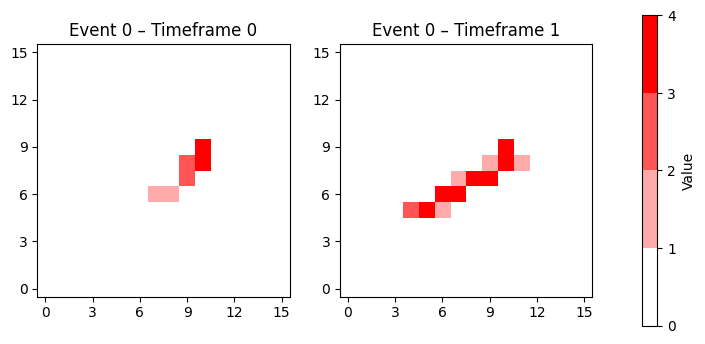

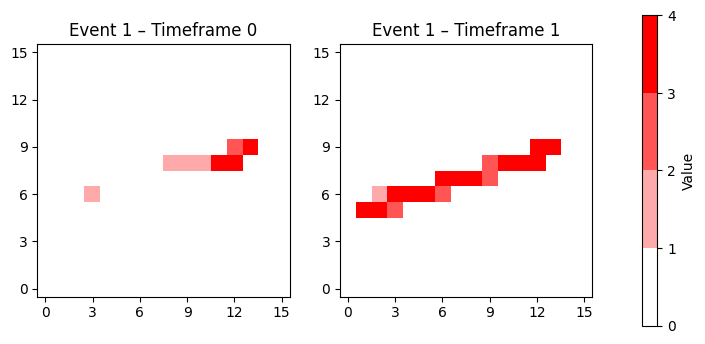

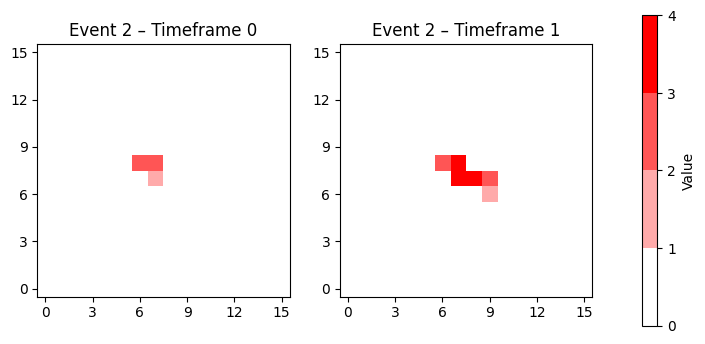

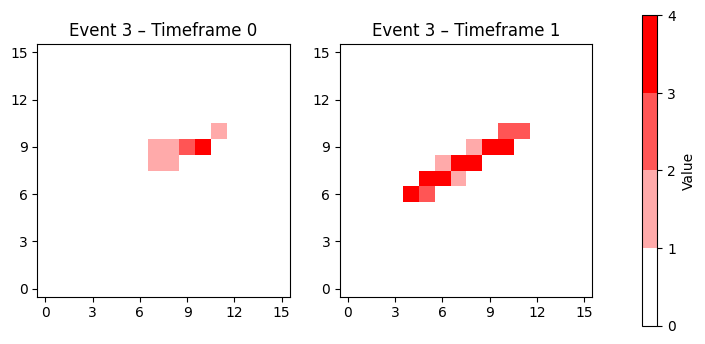

In [17]:
# Plot some events
for i in range(4):
    plot_event(X, range(2), i)

In [18]:
ani = animate_event(X, range(X.shape[3]), 0)
ani.save(f"animation_{model_type}.gif", writer="imagemagick", fps=2)
HTML(ani.to_jshtml())

### Quantize data

<b style="background-color: yellow; color: red">ATTENTION: Input quantization is disabled. Data is already quantized.</i></b>

## QKeras model

### Load QKeras model

In [19]:
# Load the whole model from HDF5 file
from tensorflow.keras.models import load_model
from qkeras.utils import _add_supported_quantized_objects

custom_loss_choices = {
    # non-quantized models
    'Conv2D_Max'  : {"custom_loss": custom_loss},
    'Conv2D_Full' : {"custom_diag_loss": custom_diag_loss},
    'Conv2D_Slim' : {"custom_sse_loss": custom_sse_loss},
    'Conv1D_Full' : {"custom_diag_loss": custom_diag_loss},
    'Conv1D_Slim' : {"custom_sse_loss": custom_sse_loss},
    'Mlp_Full'    : {"custom_diag_loss": custom_diag_loss},
    'Mlp_Slim'    : {"custom_sse_loss": custom_sse_loss},
    # quantized models
    'QConv2D_Max'  : {"custom_loss": custom_loss},
    'QConv2D_Full' : {"custom_diag_loss": custom_diag_loss},
    'QConv2D_Slim' : {"custom_sse_loss": custom_sse_loss},
    'QConv1D_Full' : {"custom_diag_loss": custom_diag_loss},
    'QConv1D_Slim' : {"custom_sse_loss": custom_sse_loss},
    'QMlp_Full'    : {"custom_diag_loss": custom_diag_loss},
    'QMlp_Slim'    : {"custom_sse_loss": custom_sse_loss},
};

co = custom_loss_choices[model_type]
_add_supported_quantized_objects(co)
model = load_model(best_model_hdf5, custom_objects=co)
model.summary(line_length=120, show_trainable=True)

Model: "smrtpxl_regression"


___________________________________________________________________________________________________________________________________


 Layer (type)                       Output Shape                        Param #     Connected to                        Trainable  


 input_pxls (InputLayer)            [(None, 16, 16, 2)]                 0           []                                  Y          


 average_pooling2d (AveragePooling  (None, 16, 1, 2)                    0           ['input_pxls[0][0]']                Y          


 2D)                                                                                                                               


... (18 outputs left out)

Total params: 2179 (8.51 KB)


Trainable params: 2179 (8.51 KB)


Non-trainable params: 0 (0.00 Byte)


___________________________________________________________________________________________________________________________________


### Run QKeras model

In [20]:
print(f'Input batch: {X.shape[0]}')
print(f'Input shape: {X.shape}')

Input batch: 255409
Input shape: (255409, 16, 16, 2)


#### QKeras Prediction

In [21]:
y_qkeras = model.predict(np.ascontiguousarray(X))
print(f'QKeras output batch: {y_qkeras.shape[0]}')
print(f'QKeras output shape: {y_qkeras.shape}')

   1/7982 [..............................] - ETA: 1:10:33

  13/7982 [..............................] - ETA: 33s    

  58/7982 [..............................] - ETA: 14s

  73/7982 [..............................] - ETA: 16s

 109/7982 [..............................] - ETA: 14s

 142/7982 [..............................] - ETA: 14s

... (254 outputs left out)

7963/7982 [============================>.] - ETA: 0s

7981/7982 [============================>.] - ETA: 0s

7982/7982 [==============================] - 14s 2ms/step


QKeras output batch: 255409
QKeras output shape: (255409, 3)


#### QKeras Profiling

In [22]:
trace_qkeras = hls4ml.model.profiling.get_ymodel_keras(model, X)

   1/7982 [..............................] - ETA: 40:54

  50/7982 [..............................] - ETA: 8s   

  98/7982 [..............................] - ETA: 8s

 139/7982 [..............................] - ETA: 8s

 188/7982 [..............................] - ETA: 8s

 230/7982 [..............................] - ETA: 8s

... (264 outputs left out)

7956/7982 [============================>.] - ETA: 0s

7980/7982 [============================>.] - ETA: 0s

7982/7982 [==============================] - 14s 2ms/step


Done taking outputs for Keras model.


In [23]:
for key in trace_qkeras.keys():
    print(f'QKeras layer trace shape: {key} {trace_qkeras[key].shape}')

QKeras layer trace shape: average_pooling2d (255409, 16, 1, 2)
QKeras layer trace shape: average_pooling2d_1 (255409, 1, 16, 2)
QKeras layer trace shape: flatten (255409, 32)
QKeras layer trace shape: flatten_1 (255409, 32)
QKeras layer trace shape: q_dense (255409, 16)
QKeras layer trace shape: q_dense_1 (255409, 16)
QKeras layer trace shape: q_activation (255409, 16)
QKeras layer trace shape: q_activation_1 (255409, 16)
QKeras layer trace shape: concatenate (255409, 32)
QKeras layer trace shape: q_dense_2 (255409, 16)
QKeras layer trace shape: q_activation_2 (255409, 16)
QKeras layer trace shape: flatten_var (255409, 16)
QKeras layer trace shape: dense_1 (255409, 16)
QKeras layer trace shape: activation_tanh_2 (255409, 16)
QKeras layer trace shape: dense_2 (255409, 16)
QKeras layer trace shape: activation_tanh_3 (255409, 16)
QKeras layer trace shape: dense_3 (255409, 3)


#### Save .dat files

In [24]:
# Save input features and model predictions
np.savetxt(f"tb_input_features_{run_tag}.dat", X.reshape(X.shape[0], -1), fmt="%f")
np.savetxt(f"tb_output_predictions_{run_tag}.dat", y_qkeras.reshape(X.shape[0], -1), fmt="%f")

In [25]:
!wc -l tb_input_features_{run_tag}.dat
!wc -l tb_output_predictions_{run_tag}.dat

255409 tb_input_features_QMlp_Slim_xc7vx485tffg1157-1.dat


255409 tb_output_predictions_QMlp_Slim_xc7vx485tffg1157-1.dat


## hls4ml model

### Configure hls4ml model

In [26]:
project_name = f"SmtPxl_{model_type}"

strategy = "Latency"
io_type = "io_parallel"
# Hardcoded weights: hls4ml writes them as constants in firmware/weights/*.h and
# Catapult can fold them into the multipliers. True exposes them as inputs (ASIC
# notebook, "_pw" in the folder name).
programmable_weights = False

# fpga_part and run_tag are set with model_type at the top of the notebook

# Same clock as the ASIC runs (25 ns, 40 MHz)
clock_period = 25

# "_efpga" keeps it apart from the ASIC projects of codesign_catapult.ipynb
hls4ml_output_dir = f"{project_name}_{io_type}_{strategy}{'_pw' if programmable_weights else ''}_efpga_hls4ml_prj"

# Run Catapult synthesis from this notebook (cells under "Model synthesis").
# True: batch flow with the fully parallel directives
# (catapult_directives/fully_parallel.tcl), then the results are read from
# rtl.rpt. False: stop before synthesis, e.g. to open the project in the
# Catapult GUI and set the directives by hand.
run_catapult_synthesis = True


In [27]:
# Remove the previous project of this notebook, and only that one.
# The folder name differs from the ASIC projects of codesign_catapult.ipynb
# (no "_pw", "_efpga" added), and the removal is checked against the
# project's own hls4ml_config.yml: a folder whose config is not this
# notebook's FPGA target (e.g. Technology asic, or BramFactor 0, i.e.
# programmable weights) is never deleted. No wildcard, unlike the ASIC
# notebook's "rm -rf $hls4ml_output_dir*".
import shutil

if not programmable_weights:
    assert "_pw" not in hls4ml_output_dir, hls4ml_output_dir
assert "_efpga_" in hls4ml_output_dir, hls4ml_output_dir

def _check_own_project(output_dir):
    cfg_file = os.path.join(output_dir, "hls4ml_config.yml")
    if not os.path.isfile(cfg_file):
        raise RuntimeError(f"{output_dir} exists but has no hls4ml_config.yml; not deleting it, remove it by hand")
    with open(cfg_file) as f:
        cfg = yaml.safe_load(f)
    bram_factor = cfg.get("HLSConfig", {}).get("Model", {}).get("BramFactor")
    problems = []
    if cfg.get("Technology") != "fpga":
        problems.append(f"Technology {cfg.get('Technology')!r}, expected 'fpga'")
    if cfg.get("Part") != fpga_part:
        problems.append(f"Part {cfg.get('Part')!r}, expected {fpga_part!r}")
    if not programmable_weights and bram_factor == 0:
        problems.append("BramFactor 0 (programmable weights)")
    if problems:
        raise RuntimeError(f"{output_dir} is not a project of this notebook ({'; '.join(problems)}); not deleting it")

if os.path.isdir(hls4ml_output_dir):
    _check_own_project(hls4ml_output_dir)
    shutil.rmtree(hls4ml_output_dir)
    print(f"removed {hls4ml_output_dir}")
if os.path.isfile(hls4ml_output_dir + ".tar.gz"):
    os.remove(hls4ml_output_dir + ".tar.gz")
    print(f"removed {hls4ml_output_dir}.tar.gz")


In [28]:
config_hls4ml = hls4ml.utils.config.create_config(
    backend = "Catapult",
    project_name = project_name,
    output_dir = hls4ml_output_dir,
    tech = "fpga",
    part = fpga_part,
    # fifo and ram keep the backend defaults (fifo None, ram
    # Xilinx_RAMS.BLOCK_1R1W_RBW); fully_parallel.tcl maps the arrays to
    # registers anyway.
    clock_period = clock_period,
    io_type = io_type,
    # Synth = False, as in codesign_catapult.ipynb: build_prj.tcl stops after
    # "go compile" in the GUI; the batch flow passes Synth=True to build().
    csim = False, SCVerify = False, Synth = False, BuildBUP = False
)

#print(json.dumps(config_hls4ml, indent=4))


In [29]:
config_hls4ml["HLSConfig"] = hls4ml.utils.config_from_keras_model(
    model,
    granularity="name",
    default_precision="ac_fixed<16,6,true>",
    default_reuse_factor=1
)

config_hls4ml["HLSConfig"]["Model"]["Strategy"] = strategy

if programmable_weights:
    # All the weights are exposed through BRAMs
    config_hls4ml["HLSConfig"]["Model"]["BramFactor"] = 0

#print(json.dumps(config_hls4ml, indent=4))

Interpreting Model
Topology:
Layer name: input_pxls, layer type: InputLayer, input shapes: [[None, 16, 16, 2]], output shape: [None, 16, 16, 2]
Layer name: average_pooling2d, layer type: AveragePooling2D, input shapes: [[None, 16, 16, 2]], output shape: [None, 16, 1, 2]
Layer name: average_pooling2d_1, layer type: AveragePooling2D, input shapes: [[None, 16, 16, 2]], output shape: [None, 1, 16, 2]
Layer name: flatten, layer type: Reshape, input shapes: [[None, 16, 1, 2]], output shape: [None, 32]
Layer name: flatten_1, layer type: Reshape, input shapes: [[None, 1, 16, 2]], output shape: [None, 32]
Layer name: q_dense, layer type: QDense, input shapes: [[None, 32]], output shape: [None, 16]
Layer name: q_dense_1, layer type: QDense, input shapes: [[None, 32]], output shape: [None, 16]
Layer name: q_activation, layer type: Activation, input shapes: [[None, 16]], output shape: [None, 16]
Layer name: q_activation_1, layer type: Activation, input shapes: [[None, 16]], output shape: [None, 16

/home/giuseppe/catapult_venvs/2024.2_2/lib/python3.10/site-packages/keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(


<b style="background-color: yellow; color: red">ATTENTION: The model precision can be fine tuned here.</b>

#### Bit-precision

In [30]:
print(model_type)

QMlp_Slim


In [31]:
match model_type:
    case 'Conv2D_Max' | 'Conv2D_Full' | 'Conv2D_Slim' | 'Conv1D_Full' | 'Conv1D_Slim' | 'Mlp_Full'  | 'Mlp_Slim' :
        # Kind of unsopported, we care about QKeras models instead, see below
        pass
    case 'QConv2D_Max'  :
        config_hls4ml["HLSConfig"]['LayerName']['input_1']['Precision']['result'] = 'ufixed<2,2>'
        config_hls4ml["HLSConfig"]['LayerName']['average_pooling2d']['Precision']['result'] = 'fixed<16,8>'
        config_hls4ml["HLSConfig"]['LayerName']['average_pooling2d']['Precision']['result'] = 'fixed<16,8>'
        config_hls4ml["HLSConfig"]['LayerName']['q_dense_2']['Precision']['result'] = 'fixed<10,4>'
        config_hls4ml["HLSConfig"]['LayerName']['q_dense_2_linear']['Precision']['result'] = 'fixed<10,4>'
    case 'QConv2D_Full' :
        config_hls4ml["HLSConfig"]['LayerName']['input_1']['Precision']['result'] = 'ufixed<2,2>'
        config_hls4ml["HLSConfig"]['LayerName']['average_pooling2d']['Precision']['result'] = 'fixed<16,8>'
        config_hls4ml["HLSConfig"]['LayerName']['average_pooling2d']['Precision']['result'] = 'fixed<16,8>'
        config_hls4ml["HLSConfig"]['LayerName']['q_dense_2']['Precision']['result'] = 'fixed<10,4>'
        config_hls4ml["HLSConfig"]['LayerName']['q_dense_2_linear']['Precision']['result'] = 'fixed<10,4>'
    case 'QConv2D_Slim' :
        config_hls4ml["HLSConfig"]['LayerName']['input_1']['Precision']['result'] = 'ufixed<2,2>'
        config_hls4ml["HLSConfig"]['LayerName']['average_pooling2d']['Precision']['result'] = 'fixed<16,8>'
        config_hls4ml["HLSConfig"]['LayerName']['average_pooling2d']['Precision']['result'] = 'fixed<16,8>'
        config_hls4ml["HLSConfig"]['LayerName']['q_dense_2']['Precision']['result'] = 'fixed<10,4>'
        config_hls4ml["HLSConfig"]['LayerName']['q_dense_2_linear']['Precision']['result'] = 'fixed<10,4>'
    case 'QConv1D_Full' :
        config_hls4ml["HLSConfig"]['LayerName']['input_pxls']['Precision']['result'] = 'ufixed<2,2>'
        config_hls4ml["HLSConfig"]['LayerName']['avg_pooling_2d_proj_x']['Precision']['result'] = 'fixed<16,8>'
        config_hls4ml["HLSConfig"]['LayerName']['avg_pooling_2d_proj_y']['Precision']['result'] = 'fixed<16,8>'
        config_hls4ml["HLSConfig"]['LayerName']['dense_3']['Precision']['result'] = 'fixed<10,4>'
        config_hls4ml["HLSConfig"]['LayerName']['dense_3_linear']['Precision']['result'] = 'fixed<10,4>'
    case 'QConv1D_Slim' :
        config_hls4ml["HLSConfig"]['LayerName']['input_pxls']['Precision']['result'] = 'ufixed<2,2>'
        config_hls4ml["HLSConfig"]['LayerName']['avg_pooling_2d_proj_x']['Precision']['result'] = 'fixed<16,8>'
        config_hls4ml["HLSConfig"]['LayerName']['avg_pooling_2d_proj_y']['Precision']['result'] = 'fixed<16,8>'
        # dense_3 widened from fixed<10,2> (range -2 to 2) to fixed<11,3> (range -4 to 4,
        # same 8 fractional bits) on 2026-10-28: the model trained 1000 + 2000 epochs
        # (3eb13b90) gives y up to 2.224 and cotB down to -2.387, and ac_fixed wraps,
        # so 45 of 255,409 test events changed sign (hls4ml test MSE 0.006616 against
        # 0.005676 for QKeras). Previous:
        # config_hls4ml["HLSConfig"]['LayerName']['dense_3']['Precision']['result'] = 'fixed<10,2>'
        # config_hls4ml["HLSConfig"]['LayerName']['dense_3_linear']['Precision']['result'] = 'fixed<10,2>'
        config_hls4ml["HLSConfig"]['LayerName']['dense_3']['Precision']['result'] = 'fixed<11,3>'
        config_hls4ml["HLSConfig"]['LayerName']['dense_3_linear']['Precision']['result'] = 'fixed<11,3>'
    case 'QMlp_Full'    :
        config_hls4ml["HLSConfig"]['LayerName']['input_pxls']['Precision']['result'] = 'ufixed<2,2>'
        config_hls4ml["HLSConfig"]['LayerName']['average_pooling2d']['Precision']['result'] = 'fixed<16,8>'
        config_hls4ml["HLSConfig"]['LayerName']['average_pooling2d_1']['Precision']['result'] = 'fixed<16,8>'
        config_hls4ml["HLSConfig"]['LayerName']['dense_3']['Precision']['result'] = 'fixed<10,4>'
        config_hls4ml["HLSConfig"]['LayerName']['dense_3_linear']['Precision']['result'] = 'fixed<10,4>'
    case 'QMlp_Slim'    :
        config_hls4ml["HLSConfig"]['LayerName']['input_pxls']['Precision']['result'] = 'ufixed<2,2>'
        # Pooling output narrowed from fixed<16,8> (codesign_catapult.ipynb) to
        # ufixed<6,2> (2026-10-27), lossless: each pooling averages 16 inputs in
        # 0..3, so every output is k/16 with k in 0..48, at most 3. The sum and the
        # division by 16 are done in accum_t (model_default_t, ac_fixed<24,10>),
        # then cast to this type. The result feeds q_dense and q_dense_1, the two
        # layers with the widest multiplies (16 x 8 bits before, 6 x 8 now).
        # Baseline run: SmtPxl_QMlp_Slim_io_parallel_Latency_efpga_pool16_8_hls4ml_prj.
        # Previous:
        # config_hls4ml["HLSConfig"]['LayerName']['average_pooling2d']['Precision']['result'] = 'fixed<16,8>'
        # config_hls4ml["HLSConfig"]['LayerName']['average_pooling2d_1']['Precision']['result'] = 'fixed<16,8>'
        config_hls4ml["HLSConfig"]['LayerName']['average_pooling2d']['Precision']['result'] = 'ufixed<6,2>'
        config_hls4ml["HLSConfig"]['LayerName']['average_pooling2d_1']['Precision']['result'] = 'ufixed<6,2>'
        config_hls4ml["HLSConfig"]['LayerName']['dense_3']['Precision']['result'] = 'fixed<10,4>'
        config_hls4ml["HLSConfig"]['LayerName']['dense_3_linear']['Precision']['result'] = 'fixed<10,4>'
    case _:
        pass 

In [32]:
# Point to the model definition, weights/biase values and C++ testbench data files
config_hls4ml["KerasH5"] = best_model_weights_hdf5
config_hls4ml["KerasJson"] = model_architecture_json
config_hls4ml["InputData"] = f"tb_input_features_{run_tag}.dat"
config_hls4ml["OutputPredictions"] = f"tb_output_predictions_{run_tag}.dat"

#print(json.dumps(config_hls4ml, indent=4))

In [33]:
# TODO: is this necessary?
with open(f"myproject_config_{run_tag}.yml", "w") as yaml_file:
    yaml.dump(config_hls4ml, yaml_file, explicit_start=False, default_flow_style=False)

In [34]:
# Enable tracing for all of the layers
for layer in config_hls4ml["HLSConfig"]["LayerName"].keys():
    print("Enable tracing for layer:", layer)
    config_hls4ml["HLSConfig"]["LayerName"][layer]["Trace"] = True

Enable tracing for layer: input_pxls
Enable tracing for layer: average_pooling2d
Enable tracing for layer: average_pooling2d_1
Enable tracing for layer: flatten
Enable tracing for layer: flatten_1
Enable tracing for layer: q_dense
Enable tracing for layer: q_dense_linear
Enable tracing for layer: q_dense_1
Enable tracing for layer: q_dense_1_linear
Enable tracing for layer: q_activation
Enable tracing for layer: q_activation_1
Enable tracing for layer: concatenate
Enable tracing for layer: q_dense_2
Enable tracing for layer: q_dense_2_linear
Enable tracing for layer: q_activation_2
Enable tracing for layer: flatten_var
Enable tracing for layer: dense_1
Enable tracing for layer: dense_1_linear
Enable tracing for layer: activation_tanh_2
Enable tracing for layer: dense_2
Enable tracing for layer: dense_2_linear
Enable tracing for layer: activation_tanh_3
Enable tracing for layer: dense_3
Enable tracing for layer: dense_3_linear


In [35]:
# Convert QKeras model to Catapult HLS C++
#
# NOTE (2026-10-18): the hls4ml shipped with Catapult 2026.3_1
# (0.1.0.dev1981+g70cf498) renamed keras_to_hls() to keras_v2_to_hls()
# (Keras 2; keras_v3_to_hls() is for Keras 3). An old keras_to_hls.py is
# still on disk, so the old name now resolves to that module and fails
# with "TypeError: 'module' object is not callable". Its layer handler
# registry is no longer populated, so it cannot be used either.
# Same signature, same config (KerasJson/KerasH5).
#
# Catapult 2026.3_1 call (disabled 2026-10-19, we use 2024.2_2):
# hls_model_hls4ml = hls4ml.converters.keras_v2_to_hls(config_hls4ml)
#
# Catapult 2024.2_2 (May 2025 slides, current):
hls_model_hls4ml = hls4ml.converters.keras_to_hls(config_hls4ml)

Interpreting Model
Topology:
Layer name: input_pxls, layer type: InputLayer, input shapes: [[None, 16, 16, 2]], output shape: [None, 16, 16, 2]
Layer name: average_pooling2d, layer type: AveragePooling2D, input shapes: [[None, 16, 16, 2]], output shape: [None, 16, 1, 2]
Layer name: average_pooling2d_1, layer type: AveragePooling2D, input shapes: [[None, 16, 16, 2]], output shape: [None, 1, 16, 2]
Layer name: flatten, layer type: Reshape, input shapes: [[None, 16, 1, 2]], output shape: [None, 32]
Layer name: flatten_1, layer type: Reshape, input shapes: [[None, 1, 16, 2]], output shape: [None, 32]
Layer name: q_dense, layer type: QDense, input shapes: [[None, 32]], output shape: [None, 16]
Layer name: q_dense_1, layer type: QDense, input shapes: [[None, 32]], output shape: [None, 16]
Layer name: q_activation, layer type: Activation, input shapes: [[None, 16]], output shape: [None, 16]
Layer name: q_activation_1, layer type: Activation, input shapes: [[None, 16]], output shape: [None, 16

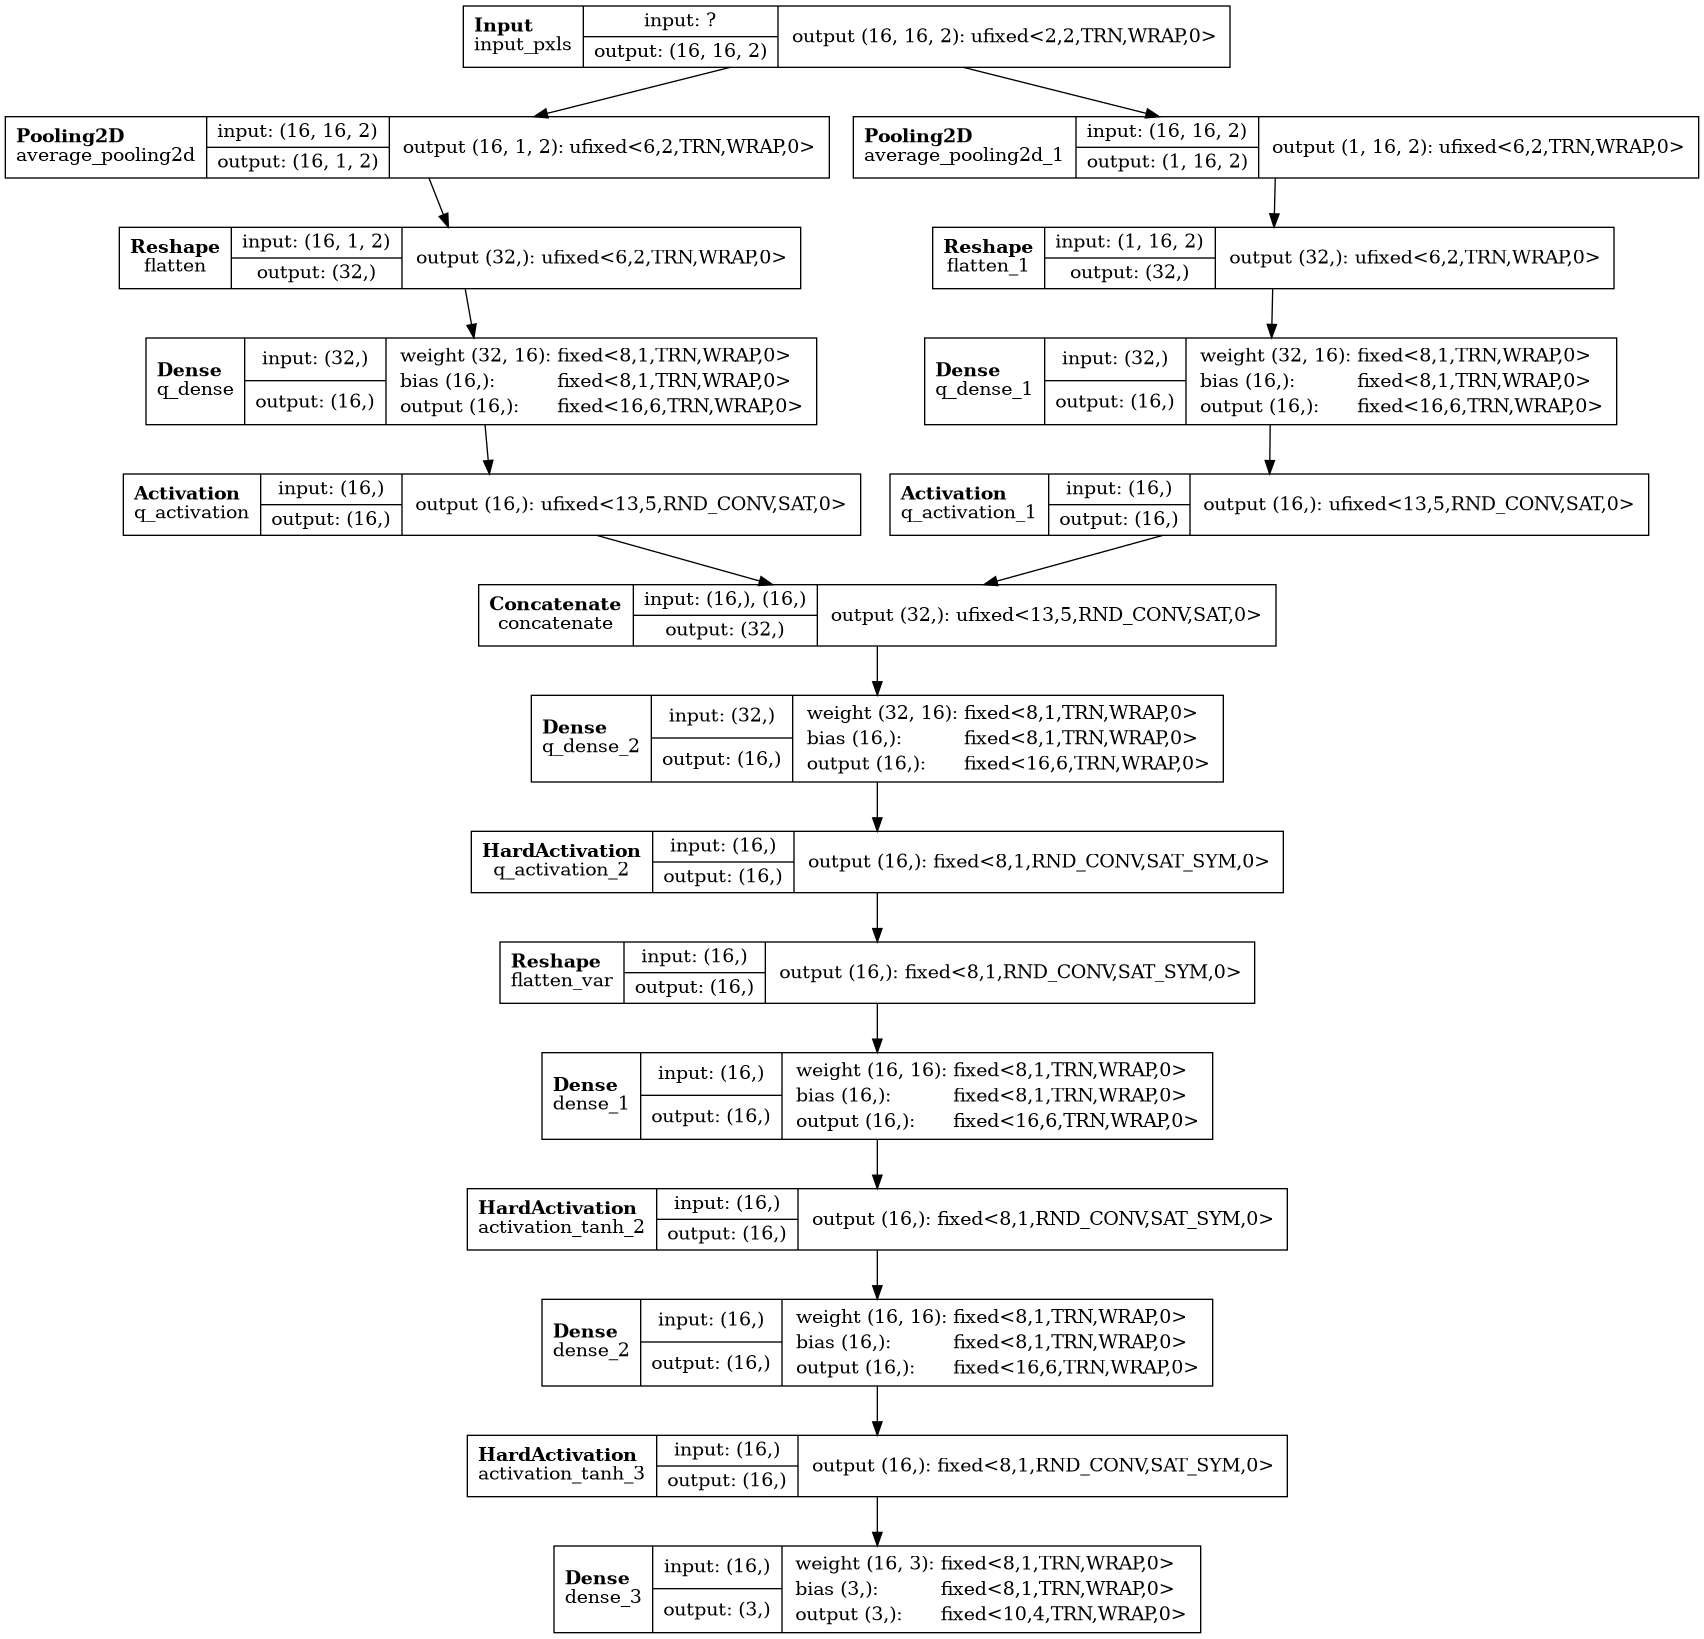

In [36]:
hls4ml.utils.plot_model(hls_model_hls4ml, show_shapes=True, show_precision=True, to_file=f"qkeras_{run_tag}.png")
hls4ml.utils.plot_model(hls_model_hls4ml, show_shapes=True, show_precision=True, to_file=None)

In [37]:
# Writing HLS project
hls_model_hls4ml.compile()

Writing HLS project


... skipping copy of NNET headers from /extras2/tools/Siemens/catapult/2024.2_2/Mgc_home/shared/include/nnet_utils/
... skipping copy of ac_types headers - assumed to located in Catapult install tree
... skipping copy of ac_math headers - assumed to located in Catapult install tree
... skipping copy of ac_simutils headers - assumed to located in Catapult install tree
Done


### Run hls4ml model

#### hls4ml Prediction

In [38]:
y_hls4ml = hls_model_hls4ml.predict(np.ascontiguousarray(X))

In [39]:
print(f'hls4ml output batch: {y_hls4ml.shape[0]}')
print(f'hls4ml output shape: {y_hls4ml.shape}')

hls4ml output batch: 255409
hls4ml output shape: (255409, 3)


#### hls4ml Profiling

In [40]:
# Run tracing on the test set for the hls4ml model (fixed-point precision) 
pred_hls4ml, trace_hls4ml = hls_model_hls4ml.trace(X)

Recompiling SmtPxl_QMlp_Slim with tracing
Writing HLS project


... skipping copy of NNET headers from /extras2/tools/Siemens/catapult/2024.2_2/Mgc_home/shared/include/nnet_utils/
... skipping copy of ac_types headers - assumed to located in Catapult install tree
... skipping copy of ac_math headers - assumed to located in Catapult install tree
... skipping copy of ac_simutils headers - assumed to located in Catapult install tree
Done


## Compare QKeras and hls4ml

### Trace visual inspection

### MSE per layer

In [41]:
print(model_type)

QMlp_Slim


In [42]:
def mse(actual, predicted):
    return ((actual - predicted) ** 2).mean()

# print(trace_hls4ml.keys())
# print(trace_hls4ml['q_separable_conv2d_pointwise'].shape)
# print(trace_qkeras['q_separable_conv2d'].shape)
 
for key in trace_hls4ml.keys():
    if key == "q_separable_conv2d_depthwise":
        continue
    print("-------")
    print("MSE {} {}".format(
        key.replace("_pointwise", ""),
        mse(
            trace_hls4ml[key].flatten(), 
            trace_qkeras[key.replace("_pointwise", "")].flatten())))

-------
MSE average_pooling2d 0.0
-------
MSE average_pooling2d_1 0.0
-------
MSE q_dense 1.1759005502653963e-07
-------
MSE q_dense_1 1.173377270902165e-07
-------
MSE q_activation 3.943756041735469e-07
-------
MSE q_activation_1 4.6777307716183714e-07
-------
MSE concatenate 4.31074340667692e-07
-------
MSE q_dense_2 1.6854040723046637e-06
-------
MSE q_activation_2 6.747534371243091e-06
-------
MSE dense_1 1.81846280611353e-05
-------
MSE activation_tanh_2 1.956179221451748e-05
-------
MSE dense_2 3.9670161640970036e-05
-------
MSE activation_tanh_3 4.0477531001670286e-05
-------
MSE dense_3 0.00011579505371628329


### Parity plots

We use [parity plots](https://en.wikipedia.org/wiki/Parity_plot) to compare _hls4ml_ and QKeras implementations of each layer.
- If the _hls4ml_ implementation is accurate (i.e. matches QKeras implementation), the ouput values should lie close to the diagonal line `y=x`, indicating equivalence.
- Deviations from this line highlight inaccuracies or implementation errors.

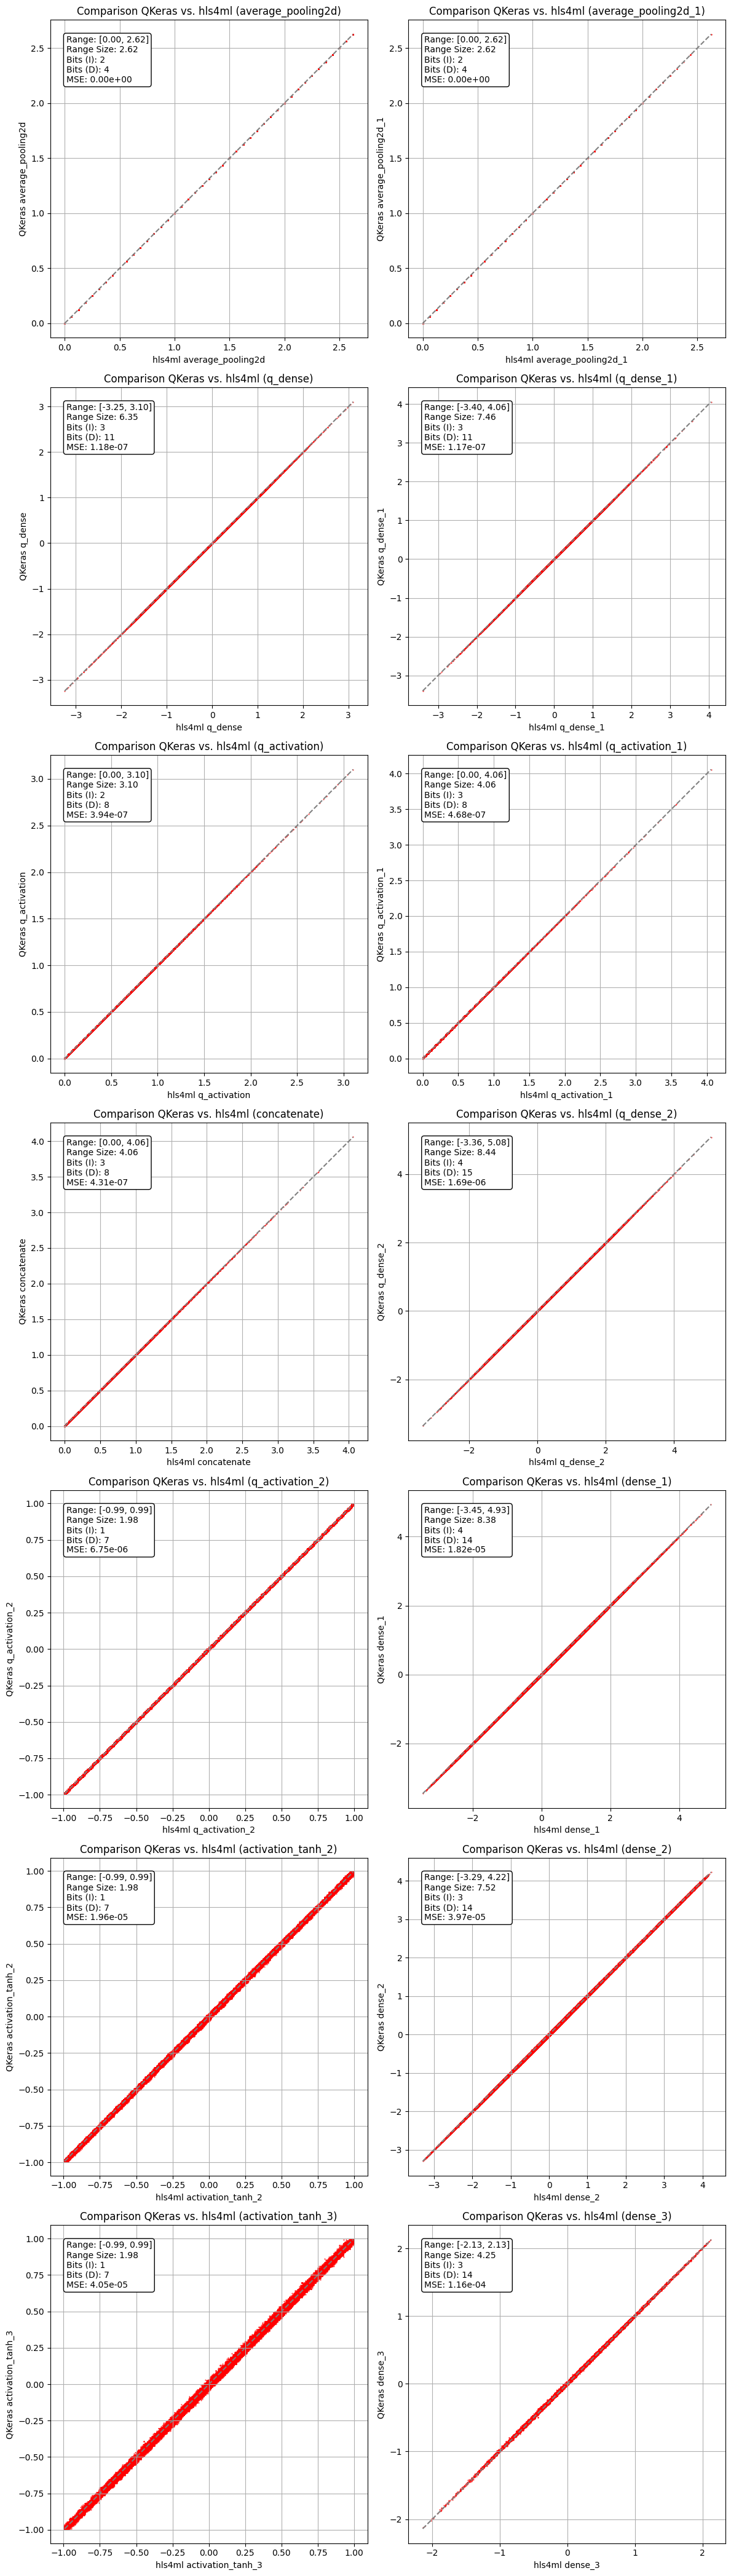

In [43]:
plot_layer_comparisons(trace_hls4ml, trace_qkeras, save_path=f"comparison_qkeras_hls4ml_{run_tag}.jpeg")

### Performance Variables

In [44]:
print(model_type)

QMlp_Slim


In [45]:
import os
import pandas as pd

# Same directory two_bit_optimization.ipynb writes its QKeras results to
# (performance_directory_2s_roi), so both land side by side. The filename carries a
# -hls4ml- infix, so it cannot collide with the QKeras "-vars.parquet".
vars_dir = (
    "./smart-pixels-ml/processed_parquets/"
    "dataset_2s_roi/"
    "test_dataset_2s_48x192_50x12P5_roi/2bit_optimized"
)

def save_performance_variables(df: pd.DataFrame, model_type: str, fingerprint: str) -> None:
    os.makedirs(vars_dir, exist_ok=True)
    vars_file = "{}/2t-{}-2bit_optimized-{}-hls4ml-{}-vars.parquet".format(
        vars_dir, model_type, fingerprint, fpga_part
    )
    print(vars_file)
    df.to_parquet(vars_file)

if model_type in ('QConv2D_Max',):
    # True values/Labels (QKeras)
    df = pd.DataFrame(
        y, 
        columns=[
            'xtrue',
            'ytrue',
            'cotAtrue',
            'cotBtrue',
        ]
    )

    # Predicted values (hls4ml)
    df['x']                = y_hls4ml[:, 0]
    df['M11']              = y_hls4ml[:, 1]
    df['y']                = y_hls4ml[:, 2]
    df['M22']              = y_hls4ml[:, 3]
    df['cotA']             = y_hls4ml[:, 4]
    df['M33']              = y_hls4ml[:, 5]
    df['cotB']             = y_hls4ml[:, 6]
    df['M44']              = y_hls4ml[:, 7]
    df['M21']              = y_hls4ml[:, 8]
    df['M31']              = y_hls4ml[:, 9]
    df['M32']              = y_hls4ml[:,10]
    df['M41']              = y_hls4ml[:,11]
    df['M42']              = y_hls4ml[:,12]
    df['M43']              = y_hls4ml[:,13]

    # Residuals (true - predicted) WITH PARENTHESES
    df['residuals_x']                 = df['xtrue']                - df['x']
    df['residuals_y']                 = df['ytrue']                - df['y']
    df['residuals_cotA']              = df['cotAtrue']             - df['cotA']
    df['residuals_cotB']              = df['cotBtrue']             - df['cotB']

    # Sigmas
    for m in ["M11","M22","M33","M44"]:
            df[m] = 1e-9 + tf.math.maximum(df[m], 0.0)
    
    df["sigmax"]           = abs(df["M11"])
    df["sigmay"]           = np.sqrt(df["M21"]**2 + df["M22"]**2)
    df["sigmacotA"]        = np.sqrt(df["M31"]**2 + df["M32"]**2 + df["M33"]**2)
    df["sigmacotB"]        = np.sqrt(df["M41"]**2 + df["M42"]**2 + df["M43"]**2 + df["M44"]**2)

    save_performance_variables(df, model_type, fingerprint)

elif model_type in ('QConv2D_Full', 'QConv1D_Full', 'QMlp_Full'):
    # True values/Labels (QKeras)
    df = pd.DataFrame(
        y,
        columns=[
            'xtrue',
            'ytrue',
            'cotAtrue',
            'cotBtrue'
        ]
    )

    # Predicted values (hls4ml)
    df['x']         = y_hls4ml[:, 0]
    df['y']         = y_hls4ml[:, 1]
    df['cotA']      = y_hls4ml[:, 2]
    df['cotB']      = y_hls4ml[:, 3]
    df['M11']       = y_hls4ml[:, 4]
    df['M22']       = y_hls4ml[:, 5]
    df['M33']       = y_hls4ml[:, 6]
    df['M44']       = y_hls4ml[:, 7]

    # Residuals
    df['residuals_x']         = df['xtrue']         - df['x']
    df['residuals_y']         = df['ytrue']         - df['y']
    df['residuals_cotA']      = df['cotAtrue']      - df['cotA']
    df['residuals_cotB']      = df['cotBtrue']      - df['cotB']

    # Sigmas
    mapping = {
            'M11': 'sigmax',
            'M22': 'sigmay',
            'M33': 'sigmacotA',
            'M44': 'sigmacotB',
        }
    for m, new_name in mapping.items():
        df[new_name] = tf.nn.softplus(df[m]) + 1e-9

    save_performance_variables(df, model_type, fingerprint)


elif model_type in ('QConv2D_Slim', 'QConv1D_Slim', 'QMlp_Slim'):
    # True values/Labels (QKeras)
    df = pd.DataFrame(
        y, 
        columns=[
            'xtrue',
            'ytrue',
            'cotBtrue'
        ]
    )

    # Predicted values (hls4ml)
    df['x']        = y_hls4ml[:, 0]
    df['y']        = y_hls4ml[:, 1]
    df['cotB']     = y_hls4ml[:, 2]

    # Residuals
    df['residuals_x']        = df['xtrue']    - df['x']
    df['residuals_y']        = df['ytrue']    - df['y']
    df['residuals_cotB']     = df['cotBtrue'] - df['cotB']

    save_performance_variables(df, model_type, fingerprint)

else:
    pass


./smart-pixels-ml/processed_parquets/dataset_2s_roi/test_dataset_2s_48x192_50x12P5_roi/2bit_optimized/2t-QMlp_Slim-2bit_optimized-392456de-hls4ml-xc7vx485tffg1157-1-vars.parquet


## Model synthesis

In [46]:
print(f'Catapult hls4ml project: {os.getcwd()}/{hls4ml_output_dir}')

Catapult hls4ml project: /extras2/home/gdg/research/projects/smartpixels/davidgjiang-smart-pixels-ml/SmtPxl_QMlp_Slim_io_parallel_Latency_efpga_hls4ml_prj


Catapult synthesis, two ways (updated 2026-10-27):

1. **Batch, from this notebook** (`run_catapult_synthesis = True`, the default). The next cells add
   `source catapult_directives/fully_parallel.tcl` after `go assembly` in `build_prj.tcl`, run
   `build(Synth=True)` and read the totals from `rtl.rpt`. The directives pipeline the main loop with
   II=1, unroll every other loop and map the arrays to registers, without naming any layer, so the
   same script works for any io_parallel model. Catapult needs the license (VPN on). Its output goes
   to the terminal of the Jupyter server and to `catapult.log` in the project folder, not to the cell.

2. **By hand, in the GUI** (`run_catapult_synthesis = False`):

```
cd SmtPxl_QMlp_Slim_io_parallel_Latency_efpga_hls4ml_prj
source ../envsetup.sh        # Catapult 2024.2_2 (default) and license, needs the VPN
catapult -f build_prj.tcl    # GUI; Synth = False, so it stops after go compile
# in the transcript:
#   go assembly
#   source ../catapult_directives/fully_parallel.tcl
#   go extract
#   flow run /HLS4ML/collect_reports
```
Then set `run_catapult_synthesis = False` and run the "Results" cells.

History: until 2026-10-26 these instructions said to edit `build_prj.tcl` to `Synth False`, run
`catapult -f built_prj.tcl` (typo) and set "top/main loop pipeline II=1, unroll all of the other
loops" in the GUI. The directives found that way for QMlp_Slim are in `catapult_directives/QMlp_Slim.tcl`.


In [47]:
# Add the fully parallel directives to build_prj.tcl (2026-10-27).
# Inserts "source catapult_directives/fully_parallel.tcl" after "go assembly" in
# the synthesis block. Run it right before build(): hls4ml rewrites build_prj.tcl
# on every write() (compile(), trace(), ...). Running it twice does nothing.
# Code and details: two_bit_optimization_helpers/catapult_flow.py.
from two_bit_optimization_helpers.catapult_flow import (
    add_directives_to_build_script,
    read_rtl_summary,
    print_rtl_summary,
)

if run_catapult_synthesis:
    add_directives_to_build_script(hls4ml_output_dir)


SmtPxl_QMlp_Slim_io_parallel_Latency_efpga_hls4ml_prj/build_prj.tcl: added 'source /extras2/home/gdg/research/projects/smartpixels/davidgjiang-smart-pixels-ml/catapult_directives/fully_parallel.tcl' after go assembly


In [48]:
%%time
# Batch Catapult synthesis (2026-10-27). Synth=True overrides Synth = False from
# create_config, so build_prj.tcl itself still stops after go compile in the GUI.
# Takes several minutes; see catapult.log in the project folder for progress.
#
# Previous (raw, never used with 2024.2_2):
# report = hls_model_hls4ml.build(csim=True, synth=False, cosim=False, validation=False, BuildBUP=build_bup)
if run_catapult_synthesis:
    report = hls_model_hls4ml.build(csim=False, Synth=True, SCVerify=False, BuildBUP=False)
    # build() does not raise when Catapult fails (e.g. no license: VPN off),
    # so check for its report here instead of failing later in the Results cells
    from two_bit_optimization_helpers.catapult_flow import find_rtl_report
    try:
        print(f"Catapult report: {find_rtl_report(hls4ml_output_dir, project_name)}")
    except FileNotFoundError as e:
        raise RuntimeError(f"Catapult synthesis did not produce rtl.rpt. Is the license "
                           f"reachable (VPN on)? Check catapult.log in {hls4ml_output_dir}") from e
else:
    print("run_catapult_synthesis = False: synthesis skipped")


Catapult backend build() option overrides: "reset=False csim=False Synth=True SCVerify=False BuildBUP=False"
catapult -product ultra -shell -f build_prj.tcl -eval 'set ::argv "reset=False csim=False Synth=True SCVerify=False BuildBUP=False"'
//  Catapult Ultra Synthesis 2024.2_2/1156857 (Production Release) Tue Jan 14 16:38:07 PST 2025
//  
//          Copyright (c) Siemens EDA, 1996-2025, All Rights Reserved.
//                        UNPUBLISHED, LICENSED SOFTWARE.
//             CONFIDENTIAL AND PROPRIETARY INFORMATION WHICH IS THE
//                   PROPERTY OF SIEMENS EDA OR ITS LICENSORS.
//  
//  Running on Linux giuseppe@thorin:2249860 6.8.0-47-generic x86_64 aol
//  
//  Package information: SIFLIBS v27.2_2.0, HLS_PKGS v27.2_2.0, 
//                       SIF_TOOLKITS v27.2_2.0, SIF_XILINX v27.2_2.0, 
//                       SIF_ALTERA v27.2_2.0, CCS_LIBS v27.2_2.0, 
//                       CDS_PPRO v2024.1_3, CDS_DesignChecker v2024.2_1, 
//                       CDS_OASY

# Connected to license server 1717@fasic-135413.fnal.gov (LIC-13)
# Catapult product license successfully checked out, elapsed time 00:03 (LIC-14)


dofile ./build_prj.tcl
# > array set BuildOptions {
# >   reset           0
# >   csim False
# >   SCVerify False
# >   Synth False
# >   vhdl 1
# >   verilog 1
# >   RTLSynth 0
# >   RandomTBFrames 2
# >   PowerEst 0
# >   PowerOpt 0
# >   BuildBUP False
# >   BUPWorkers 0
# >   LaunchDA 0
# >   startup {}
# > }
# > set sfd [file dirname [info script]]
# .
# > if { [info exists ::argv] } {
# >   foreach arg $::argv {
# >     foreach {optname optval} [split $arg '='] {}
# >     set mapping {"cosim" "SCVerify" "validation" "SCVerify" "synth" "Synth" "vsynth" "RTLSynth" "ran_frame" "RandomTBFrames" "sw_opt" "PowerEst" "power" "PowerOpt" "da" "LaunchDA" "bup" "BuildBUP"}
# >     set pos [lsearch -exact $mapping $optname]
# >     if { ($pos != -1) && ([expr $pos % 2] == 0) } {
# >       set oldoptname $optname
# >       set optname [lindex $mapping [expr $pos + 1]]
# >       logfile message "HLS4ML build() option '$oldoptname' is being depricated. Use '$optname'\n" warning
# >     }
# >   

# > options set Message/ErrorOverride HIER-10 -remove
# ASM-11 ASM-48 ASM-63 ASM-69 ASSERT-1 CIN-8 CIN-17 CIN-46 CIN-48 CIN-49 CIN-50 CIN-54 CIN-84 CIN-87 CIN-109 CIN-110 CIN-111 CIN-112 CIN-188 CIN-214 CIN-243 CIN-244 CLUSTER-3 CNS-9 CRAAS-21 DIR-24 DIR-32 HIER-2 HIER-20 HIER-45 IFSYN-6 INCR-13 INCR-14 INCR-15 LIB-194 LIB-204 LIB-211 LIB-224 LOOP-21 MEM-65 MEM-78 MEM-82 MEM-83 MEM-88 MGEN-16 NL-21 NL-26 NL-30 NL-35 OPT-25 READ-8 READ-9 SCHD-37 SCHD-54 SCHD-55 SIF-6 SIF-17 SIF-20
# > solution options set Message/ErrorOverride HIER-10 -remove
# ASM-11 ASM-48 ASM-63 ASM-69 ASSERT-1 CIN-8 CIN-17 CIN-46 CIN-48 CIN-49 CIN-50 CIN-54 CIN-84 CIN-87 CIN-109 CIN-110 CIN-111 CIN-112 CIN-188 CIN-214 CIN-243 CIN-244 CLUSTER-3 CNS-9 CRAAS-21 DIR-24 DIR-32 HIER-2 HIER-20 HIER-45 IFSYN-6 INCR-13 INCR-14 INCR-15 LIB-194 LIB-204 LIB-211 LIB-224 LOOP-21 MEM-65 MEM-78 MEM-82 MEM-83 MEM-88 MGEN-16 NL-21 NL-26 NL-30 NL-35 OPT-25 READ-8 READ-9 SCHD-37 SCHD-54 SCHD-55 SIF-6 SIF-17 SIF-20
# > options set Messa

# $MGC_HOME/shared/include/ac_std_float.h(192): Pragma 'hls_design<>' detected on routine 'ac::fx_div<8>' (CIN-6)


# $MGC_HOME/shared/include/nnet_utils/nnet_activation.h(72): Pragma 'hls_design<>' detected on routine 'nnet::relu<q_dense_result_t, layer10_t, relu_config10>' (CIN-6)
# Warning: $MGC_HOME/shared/include/nnet_utils/nnet_activation.h(75): Cannot bind pragma 'hls_pipeline_init_interval 1' to any valid construct. Please check if a valid construct follows the pragma. (CIN-319)
# $MGC_HOME/shared/include/nnet_utils/nnet_activation.h(72): Pragma 'hls_design<>' detected on routine 'nnet::relu<q_dense_1_result_t, layer11_t, relu_config11>' (CIN-6)
# Warning: $MGC_HOME/shared/include/nnet_utils/nnet_activation.h(75): Cannot bind pragma 'hls_pipeline_init_interval 1' to any valid construct. Please check if a valid construct follows the pragma. (CIN-319)
# Warning: $MGC_HOME/shared/include/nnet_utils/nnet_activation.h(690): Cannot bind pragma 'hls_pipeline_init_interval 1' to any valid construct. Please check if a valid construct follows the pragma. (CIN-319)
# Warning: $MGC_HOME/shared/include/n

... (80 outputs left out)

# > if {$BuildOptions(SCVerify) } {
# >   if {$BuildOptions(verilog)} {
# >     flow run /SCVerify/launch_make ./scverify/Verify_rtl_v_msim.mk {} SIMTOOL=msim sim
# >   }
# >   if {$BuildOptions(vhdl)} {
# >     flow run /SCVerify/launch_make ./scverify/Verify_rtl_vhdl_msim.mk {} SIMTOOL=msim sim
# >   }
# > }
# > if {$BuildOptions(PowerEst)} {
# >   puts "***** Pre Power Optimization *****"
# >   go switching
# >   if {$BuildOptions(verilog)} {
# >     flow run /PowerAnalysis/report_pre_pwropt_Verilog
# >   }
# >   if {$BuildOptions(vhdl)} {
# >     flow run /PowerAnalysis/report_pre_pwropt_VHDL
# >   }
# > }
# > if {$BuildOptions(PowerOpt)} {
# >   puts "***** Power Optimization *****"
# >   go power
# > }
# > if {$BuildOptions(RTLSynth)} {
# >   set launch {}
# >   foreach {p v} [solution get /OUTPUTFILES/.../FILETYPE -match glob -rec 1 -ret pv] {
# >     if { $v == "SYNTHESIS" } {
# >       set p1 [file dirname $p]
# >       set nettype [string tolower [solution get $p1/DEPENDENCIE

# Warning: Block latency data is currently not available in bottom-up synthesis
# Info: Generated HLS4ML nnet layer post-HLS report '/extras2/home/gdg/research/projects/smartpixels/davidgjiang-smart-pixels-ml/SmtPxl_QMlp_Slim_io_parallel_Latency_efpga_hls4ml_prj/SmtPxl_QMlp_Slim_prj/SmtPxl_QMlp_Slim.v1/nnet_layer_results.txt'
# Info: ====================
# Info: HLS4ML 'nnet' Layer Results
# Info: 
# Info: Layer                                                       Unroll    II        Area       Latency       Thruput      TotalPwr        DynPwr       LeakPwr
# Info: -------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------
# Info: 
# Info: 
# Info: FIFO Interconnect
# Info: C++ Variable               Instance                   Component                     Width     Depth      Area
# Info: -------------------------  -------------------------  -------------------------  --------

# > end dofile ./build_prj.tcl


Utilization report not found.
Timing report not found.
Results in nnet_layer_results.txt from: SmtPxl_QMlp_Slim_io_parallel_Latency_efpga_hls4ml_prj/SmtPxl_QMlp_Slim_prj/SmtPxl_QMlp_Slim.v1/nnet_layer_results.txt
CPU times: user 165 ms, sys: 61.7 ms, total: 227 ms
Wall time: 7min 20s


### Results

In [49]:
# Per-layer report (nnet_layer_results.txt, written by "flow run /HLS4ML/collect_reports"
# at the end of build_prj.tcl). For io_parallel its tables are empty: build_prj.tcl inlines
# every nnet:: function into one block, so there are no layer blocks to report. The design totals are in the next cells.
catapult_full_report = hls4ml.report.parse_catapult_report(hls4ml_output_dir, project_name)


Utilization report not found.
Timing report not found.
Results in nnet_layer_results.txt from: SmtPxl_QMlp_Slim_io_parallel_Latency_efpga_hls4ml_prj/SmtPxl_QMlp_Slim_prj/SmtPxl_QMlp_Slim.v1/nnet_layer_results.txt


In [50]:
catapult_qor = hls4ml.report.qofr(catapult_full_report)


Layer
=====
-----  ------  --  ----  -------  -------  --------  ------  -------
Layer  Unroll  II  Area  Latency  Thruput  TotalPwr  DynPwr  LeakPwr
-----  ------  --  ----  -------  -------  --------  ------  -------

FIFO Interconnect
------------  --------  ---------  -----  -----  ----
C++ Variable  Instance  Component  Width  Depth  Area
------------  --------  ---------  -----  -----  ----

Weight/Bias Value ROM Constants
-----  --------  -----------
Layer  Variable  Size (bits)
-----  --------  -----------


In [51]:
# Design totals from rtl.rpt (2026-10-27): latency, throughput, area, timing.
# Code: two_bit_optimization_helpers/catapult_flow.py (read_rtl_summary).
catapult_summary = read_rtl_summary(hls4ml_output_dir, project_name)
print_rtl_summary(catapult_summary)


Catapult 2024.2_2/1156857 Production Release, solution SmtPxl_QMlp_Slim.v1
  report:            SmtPxl_QMlp_Slim_io_parallel_Latency_efpga_hls4ml_prj/SmtPxl_QMlp_Slim_prj/SmtPxl_QMlp_Slim.v1/rtl.rpt
  clock period:      25 ns
  latency:           5 cycles (125 ns)
  throughput:        1 cycle (25 ns)
  II:                1
  total area score:  266,031.0 (post-assignment)
                     267,371.0 (post-scheduling)
  register area:     0.0
  critical path:     21.49 ns, slack 3.51 ns
  real operations:   4755


In [52]:
# Check that Catapult used the Virtex-7 library for fpga_part, not the KINTEX-u
# fallback of setup_xilinx_part (build_prj.tcl). Read from rtl.rpt: catapult.log
# also echoes the source of setup_xilinx_part, fallback lines included, so
# searching it for them gives a false warning (fixed 2026-10-27).
import re
with open(catapult_summary["rtl_report"]) as f:
    _fpga_libs = sorted(set(re.findall(r"\[Lib: (mgc_Xilinx\S+)\]", f.read())))
print("FPGA library:", ", ".join(_fpga_libs) or "none found")
if any("KINTEX" in l for l in _fpga_libs) or not _fpga_libs:
    print(f"WARNING: not the Virtex-7 library for {fpga_part}; Catapult may have fallen back to KINTEX-u")


FPGA library: mgc_Xilinx-VIRTEX-7-1_beh
